In [28]:
!pip install pyod

(500, 2)


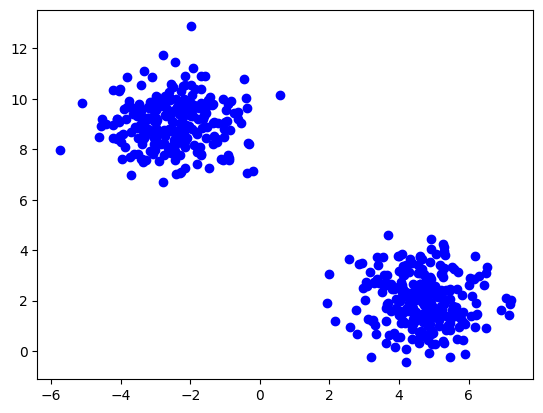

(500, 5)
[1. 1. 1. 1. 1.]




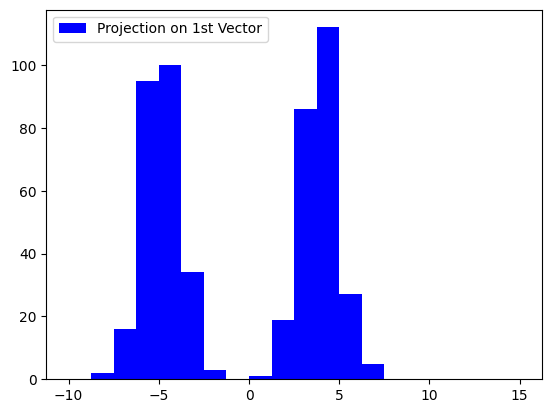

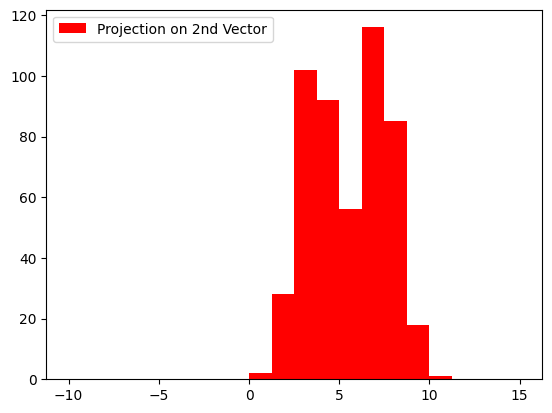

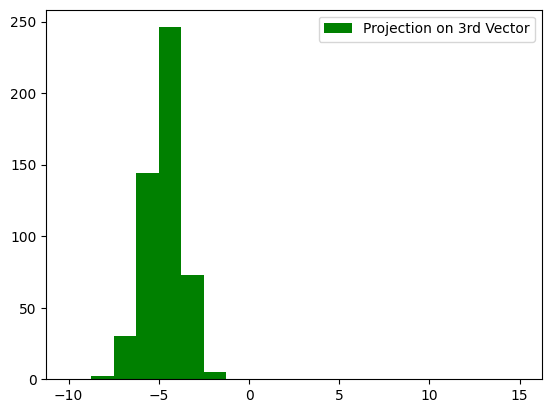

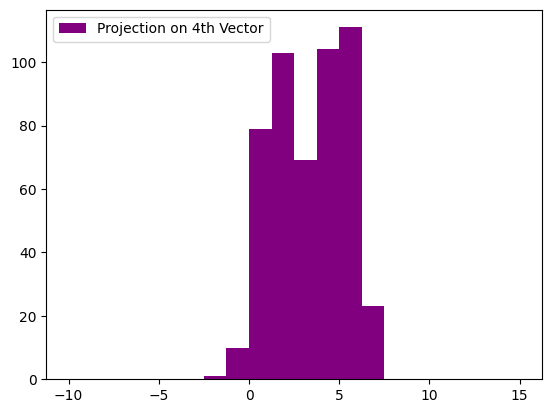

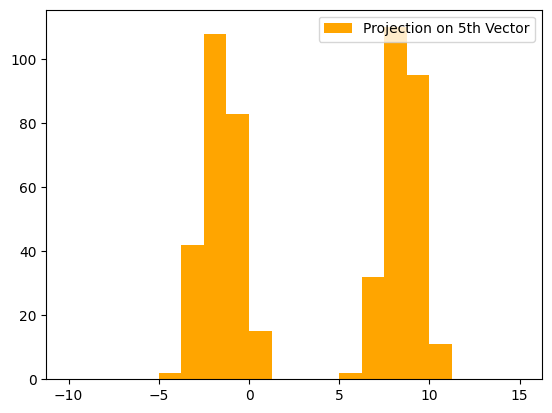

(20,)
(500,)
-7.687910049478911 11.06038985452518
(500,)
(500, 5)
(500,)


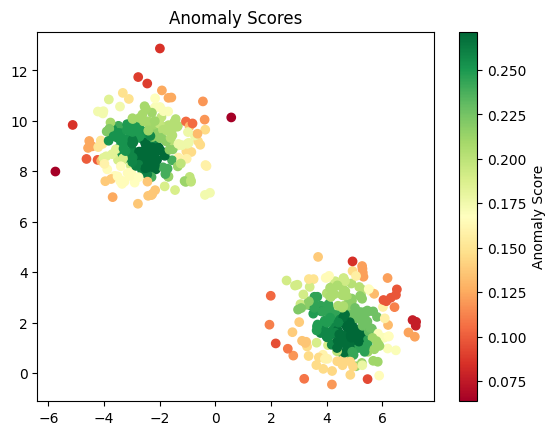

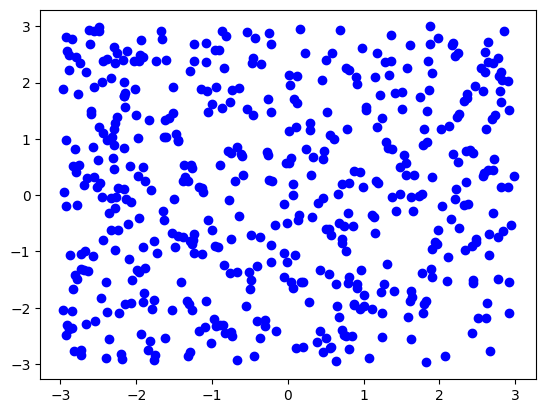

(500, 5)
(500,)


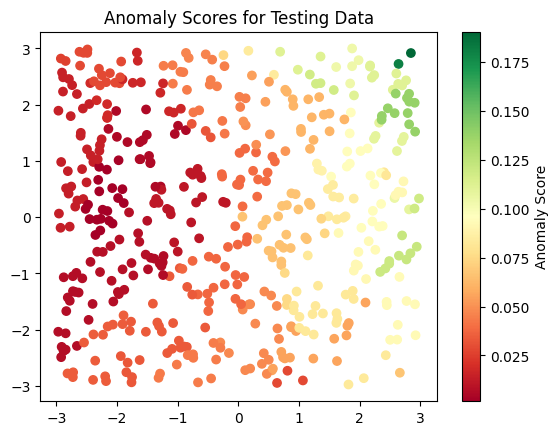

In [23]:
# Ex. 1

import numpy as np
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

X, Y = make_blobs(
    n_samples=500,
    centers=2,
    cluster_std=1,
    random_state=42
)

print(X.shape)

plt.scatter(X[:, 0], X[:, 1], color='blue')
plt.show()

mn = [0, 0]
cvm = np.identity(2)

np.random.seed(42)
V = np.random.multivariate_normal(mean=mn, cov=cvm, size=5)

LV = np.linalg.norm(V, axis=1, keepdims=True)
Vu = V / LV

Z = X @ Vu.T

print(Z.shape)
print(np.linalg.norm(Vu, axis=1))

counts1, edges1 = np.histogram(Z[:, 0], bins=20, range=(-10, 15), density=None)
counts2, edges2 = np.histogram(Z[:, 1], bins=20, range=(-10, 15), density=None)
counts3, edges3 = np.histogram(Z[:, 2], bins=20, range=(-10, 15), density=None)
counts4, edges4 = np.histogram(Z[:, 3], bins=20, range=(-10, 15), density=None)
counts5, edges5 = np.histogram(Z[:, 4], bins=20, range=(-10, 15), density=None)

print("\n")

plt.hist(Z[:, 0], bins=20, label="Projection on 1st Vector", color='blue', range=(-10, 15))
plt.legend()
plt.show()

plt.hist(Z[:, 1], bins=20, label="Projection on 2nd Vector", color='red', range=(-10, 15))
plt.legend()
plt.show()

plt.hist(Z[:, 2], bins=20, label="Projection on 3rd Vector", color='green', range=(-10, 15))
plt.legend()
plt.show()

plt.hist(Z[:, 3], bins=20, label="Projection on 4th Vector", color='purple', range=(-10, 15))
plt.legend()
plt.show()

plt.hist(Z[:, 4], bins=20, label="Projection on 5th Vector", color='orange', range=(-10, 15))
plt.legend()
plt.show()

probV1 = counts1 / np.sum(counts1)
probV2 = counts2 / np.sum(counts2)
probV3 = counts3 / np.sum(counts3)
probV4 = counts4 / np.sum(counts4)
probV5 = counts5 / np.sum(counts5)

print(probV1.shape)

indx1 = np.searchsorted(edges1, Z[:, 0], side="right") - 1
indx2 = np.searchsorted(edges2, Z[:, 1], side="right") - 1
indx3 = np.searchsorted(edges3, Z[:, 2], side="right") - 1
indx4 = np.searchsorted(edges4, Z[:, 3], side="right") - 1
indx5 = np.searchsorted(edges5, Z[:, 4], side="right") - 1

print(indx1.shape)
print(np.min(Z), np.max(Z))

P1 = probV1[indx1]
P2 = probV2[indx2]
P3 = probV3[indx3]
P4 = probV4[indx4]
P5 = probV5[indx5]

print(P1.shape)

P = np.column_stack((P1, P2, P3, P4, P5))
print(P.shape)

anmly_score = np.mean(P, axis=1)
print(anmly_score.shape)

plt.scatter(X[:, 0], X[:, 1], c=anmly_score, cmap='RdYlGn')
plt.title('Anomaly Scores')
plt.colorbar(label='Anomaly Score')
plt.show()


X_test = np.random.uniform(low=-3, high=3, size=(500, 2))

plt.scatter(X_test[:, 0], X_test[:, 1], color='blue')
plt.show()

Z_test = X_test @ Vu.T

indx1_test = np.searchsorted(edges1, Z_test[:, 0], side="right") - 1
indx2_test = np.searchsorted(edges2, Z_test[:, 1], side="right") - 1
indx3_test = np.searchsorted(edges3, Z_test[:, 2], side="right") - 1
indx4_test = np.searchsorted(edges4, Z_test[:, 3], side="right") - 1
indx5_test = np.searchsorted(edges5, Z_test[:, 4], side="right") - 1

P1_test = probV1[indx1_test]
P2_test = probV2[indx2_test]
P3_test = probV3[indx3_test]
P4_test = probV4[indx4_test]
P5_test = probV5[indx5_test]

P_test = np.column_stack((P1_test, P2_test, P3_test, P4_test, P5_test))
print(P_test.shape)

anmly_score_test = np.mean(P_test, axis=1)
print(anmly_score_test.shape)

plt.scatter(X_test[:, 0], X_test[:, 1], c=anmly_score_test, cmap='RdYlGn')
plt.title('Anomaly Scores for Testing Data')
plt.colorbar(label='Anomaly Score')
plt.show()


In [32]:
!pip install pyod

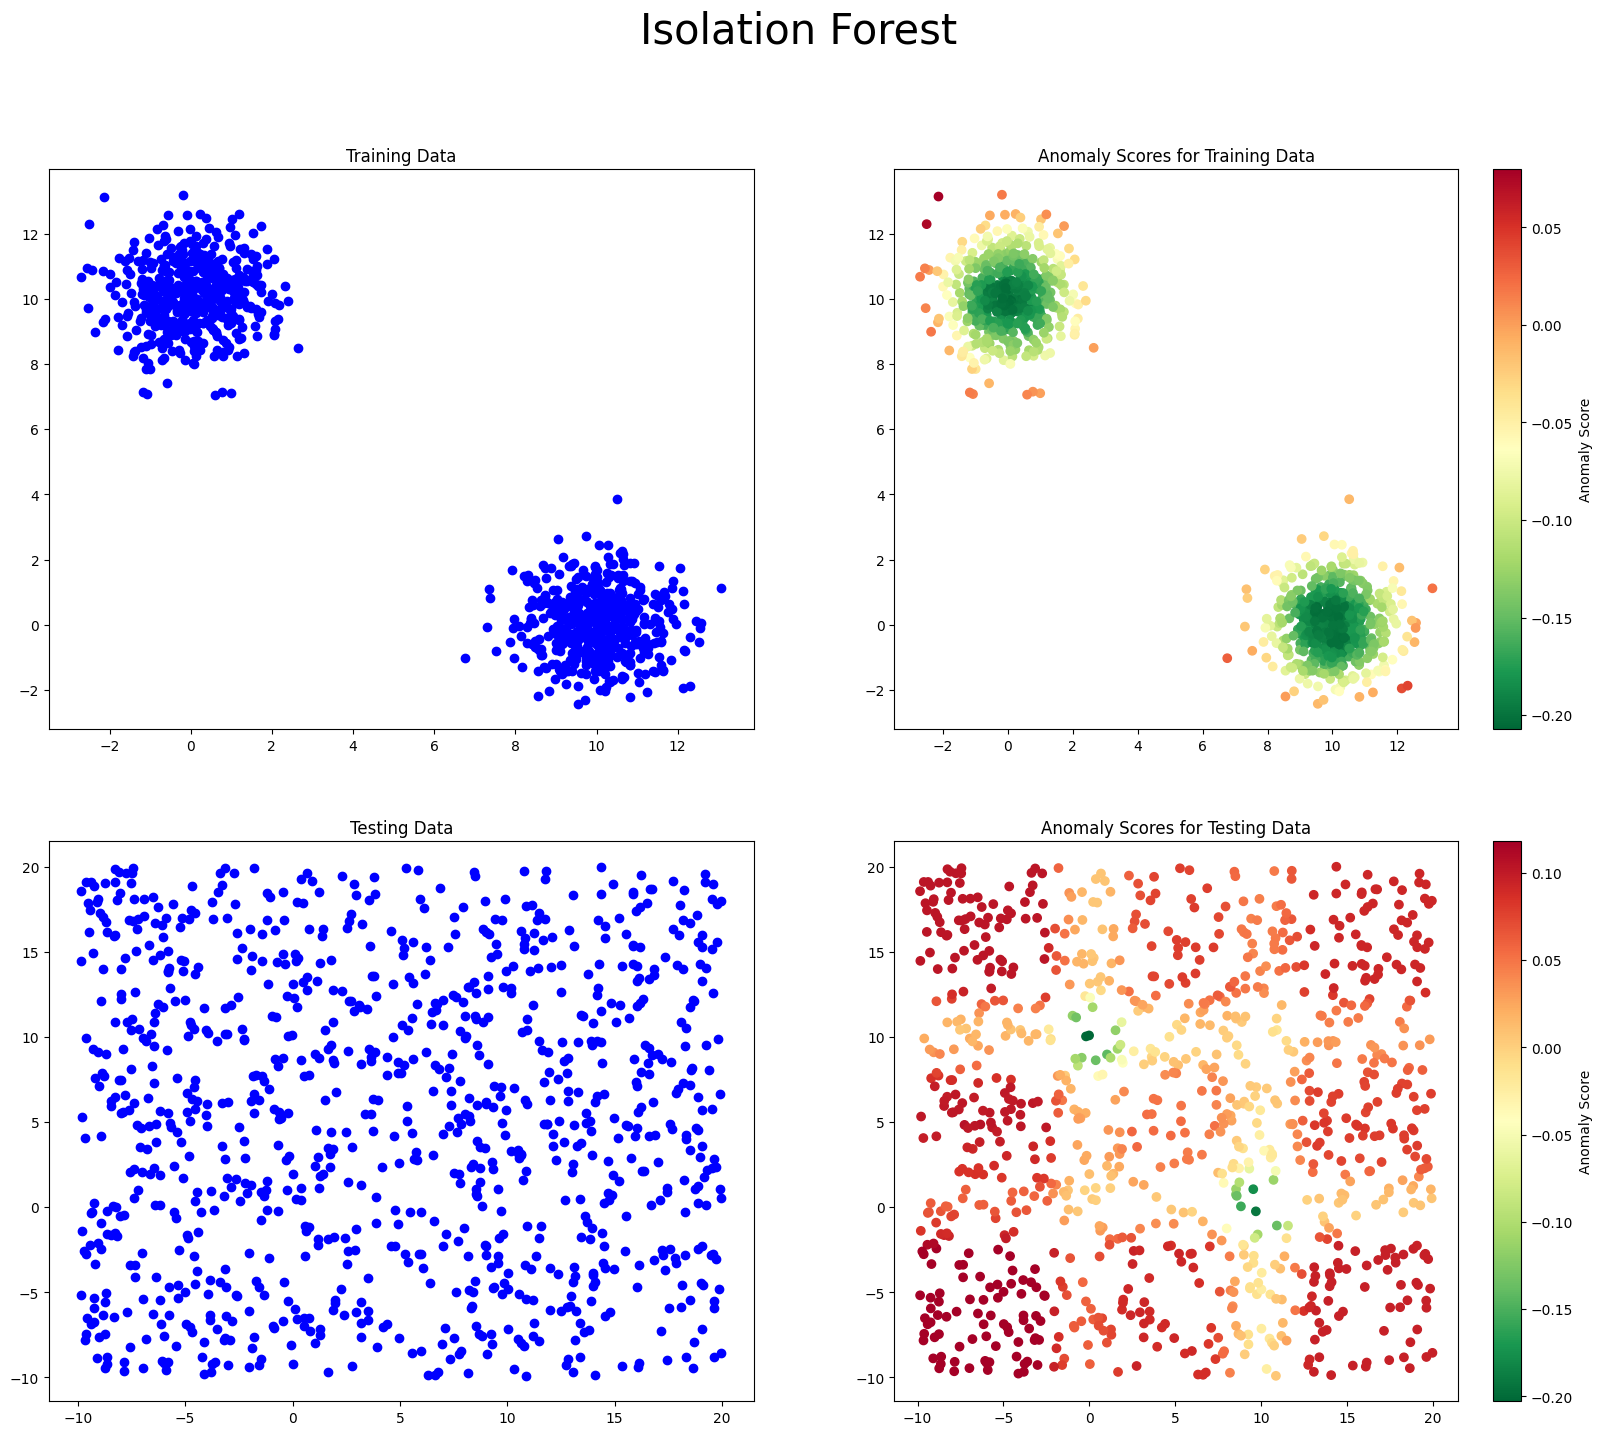

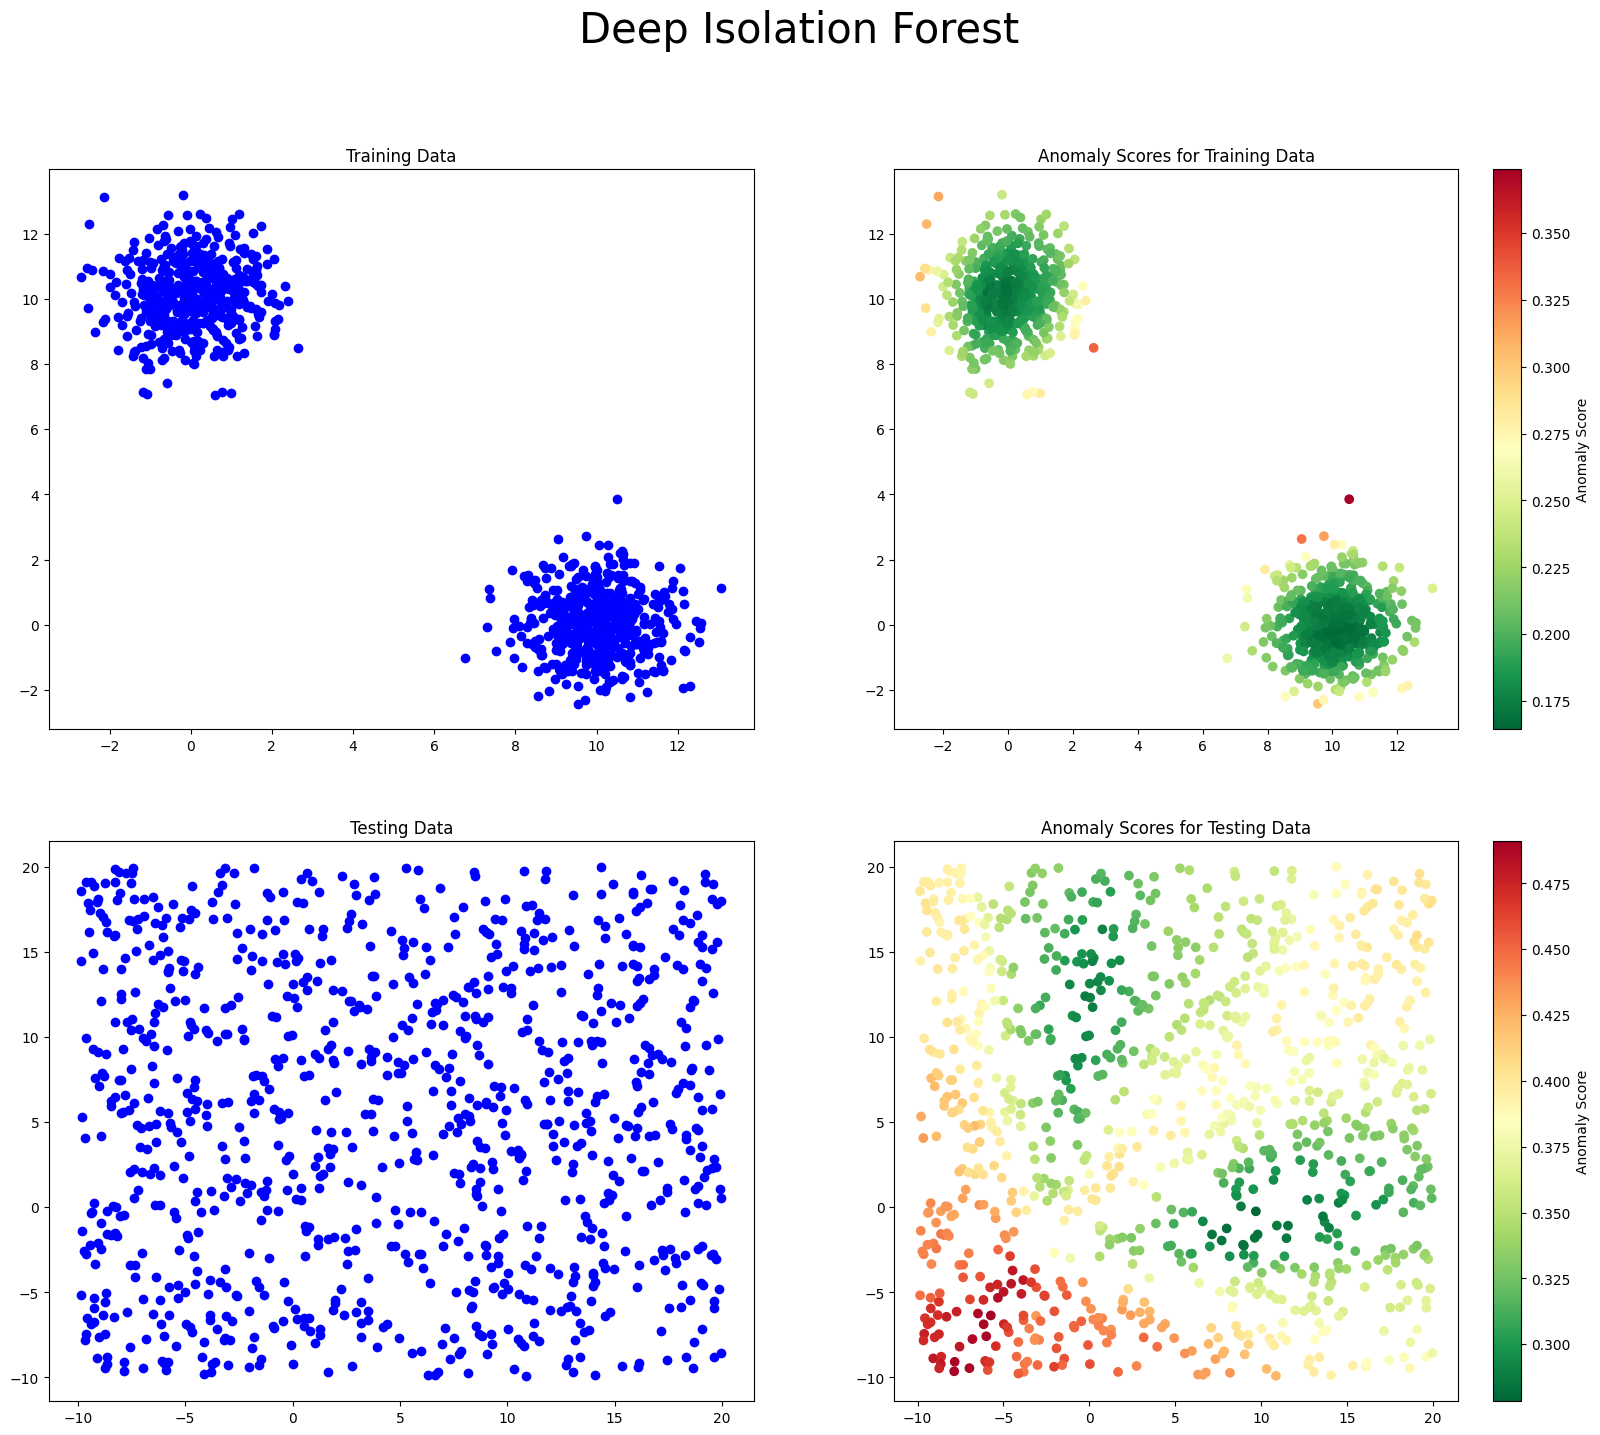

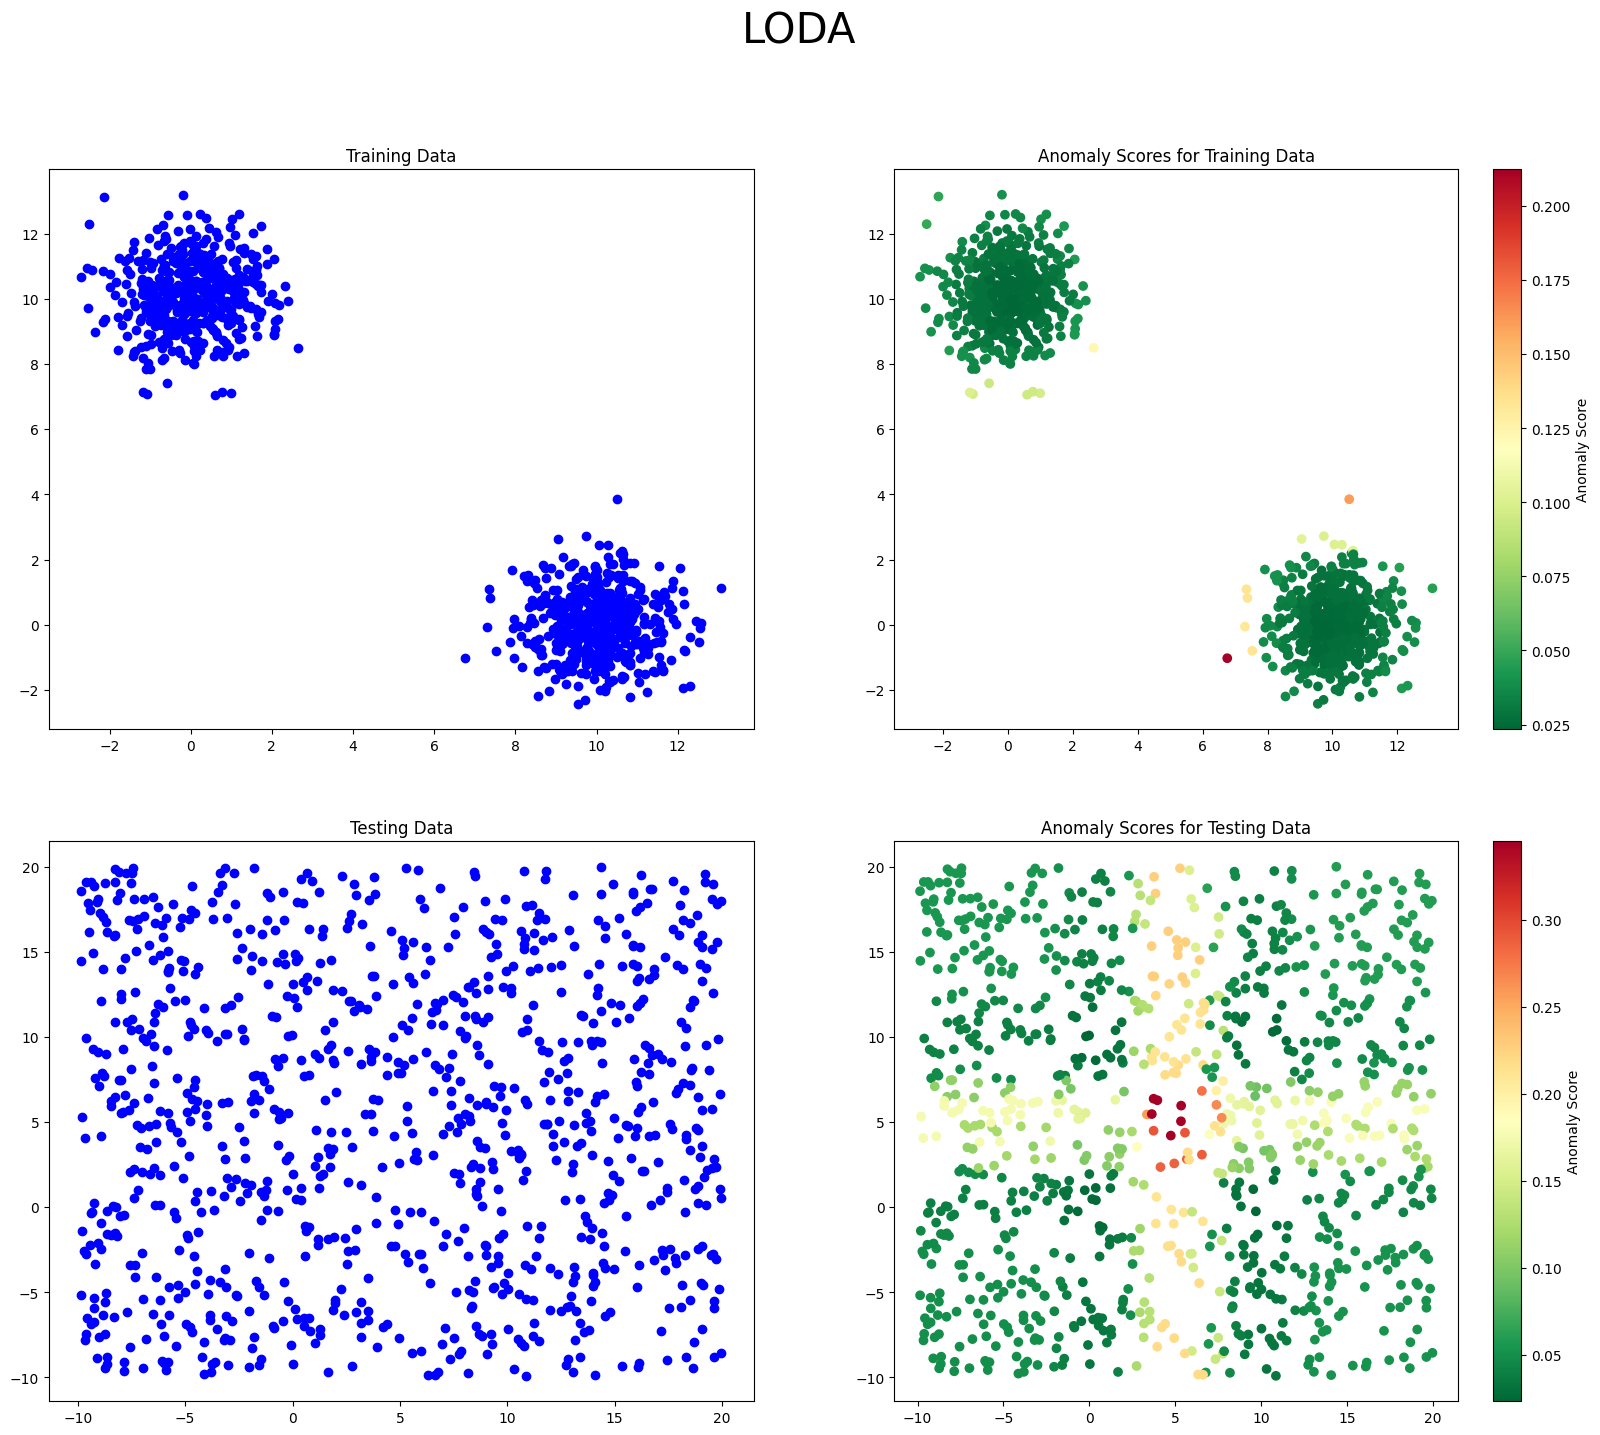

In [67]:
# Ex. 2 - 2D Points

import numpy as np
import matplotlib.pyplot as plt
from pyod.models.iforest import IForest
from pyod.models.dif import DIF
from pyod.models.loda import LODA
from sklearn.datasets import make_blobs

X_train, Y_train = make_blobs(
    n_samples=[500, 500],
    centers=[[10, 0], [0, 10]],
    cluster_std=1,
    random_state=42
)

fig, axes = plt.subplots(2, 2, figsize=(20, 16))
fig.suptitle("Isolation Forest", fontsize=30)

axes[0, 0].scatter(X_train[:, 0], X_train[:, 1], color='blue')
axes[0, 0].set_title('Training Data')

# Isolation Forest

m_IF = IForest(contamination=0.02)
m_IF.fit(X_train)

anmly_score_IF_train = m_IF.decision_scores_

grf1 = axes[0, 1].scatter(X_train[:, 0], X_train[:, 1], c=anmly_score_IF_train, cmap='RdYlGn_r')
axes[0, 1].set_title('Anomaly Scores for Training Data')

np.random.seed(42)
X_test = np.random.uniform(low=-10, high=20, size=(1000, 2))

axes[1, 0].scatter(X_test[:, 0], X_test[:, 1], color='blue')
axes[1, 0].set_title('Testing Data')

anmly_score_IF_test = m_IF.decision_function(X_test)

grf2 = axes[1, 1].scatter(X_test[:, 0], X_test[:, 1], c=anmly_score_IF_test, cmap='RdYlGn_r')
axes[1, 1].set_title('Anomaly Scores for Testing Data')

fig.colorbar(grf1, ax=axes[0,1], label='Anomaly Score')
fig.colorbar(grf2, ax=axes[1,1], label='Anomaly Score')

plt.show()

# Deep Isolation Forest

import warnings

warnings.filterwarnings(
    "ignore",
    message=".*pin_memory.*no accelerator.*",
    category=UserWarning
)

m_DIF = DIF(hidden_neurons=[100, 200, 150], contamination=0.02)
m_DIF.fit(X_train)

anmly_score_DIF_train = m_DIF.decision_scores_
anmly_score_DIF_test = m_DIF.decision_function(X_test)

fig1, axes1 = plt.subplots(2, 2, figsize=(20, 16))
fig1.suptitle("Deep Isolation Forest", fontsize=30)

axes1[0, 0].scatter(X_train[:, 0], X_train[:, 1], color='blue')
axes1[0, 0].set_title('Training Data')

grf3 = axes1[0, 1].scatter(X_train[:, 0], X_train[:, 1], c=anmly_score_DIF_train, cmap='RdYlGn_r')
axes1[0, 1].set_title('Anomaly Scores for Training Data')

axes1[1, 0].scatter(X_test[:, 0], X_test[:, 1], color='blue')
axes1[1, 0].set_title('Testing Data')

grf4 = axes1[1, 1].scatter(X_test[:, 0], X_test[:, 1], c=anmly_score_DIF_test, cmap='RdYlGn_r')
axes1[1, 1].set_title('Anomaly Scores for Testing Data')

fig1.colorbar(grf3, ax=axes1[0,1], label='Anomaly Score')
fig1.colorbar(grf4, ax=axes1[1,1], label='Anomaly Score')

plt.show()

# LODA

m_LODA = LODA(n_bins=30, contamination=0.02)
m_LODA.fit(X_train)

anmly_score_LODA_train = m_LODA.decision_scores_
anmly_score_LODA_test = m_LODA.decision_function(X_test)

fig2, axes2 = plt.subplots(2, 2, figsize=(20, 16))
fig2.suptitle("LODA", fontsize=30)

axes2[0, 0].scatter(X_train[:, 0], X_train[:, 1], color='blue')
axes2[0, 0].set_title('Training Data')

grf5 = axes2[0, 1].scatter(X_train[:, 0], X_train[:, 1], c=anmly_score_LODA_train, cmap='RdYlGn_r')
axes2[0, 1].set_title('Anomaly Scores for Training Data')

axes2[1, 0].scatter(X_test[:, 0], X_test[:, 1], color='blue')
axes2[1, 0].set_title('Testing Data')

grf6 = axes2[1, 1].scatter(X_test[:, 0], X_test[:, 1], c=anmly_score_LODA_test, cmap='RdYlGn_r')
axes2[1, 1].set_title('Anomaly Scores for Testing Data')

fig2.colorbar(grf5, ax=axes2[0,1], label='Anomaly Score')
fig2.colorbar(grf6, ax=axes2[1,1], label='Anomaly Score')

plt.show()





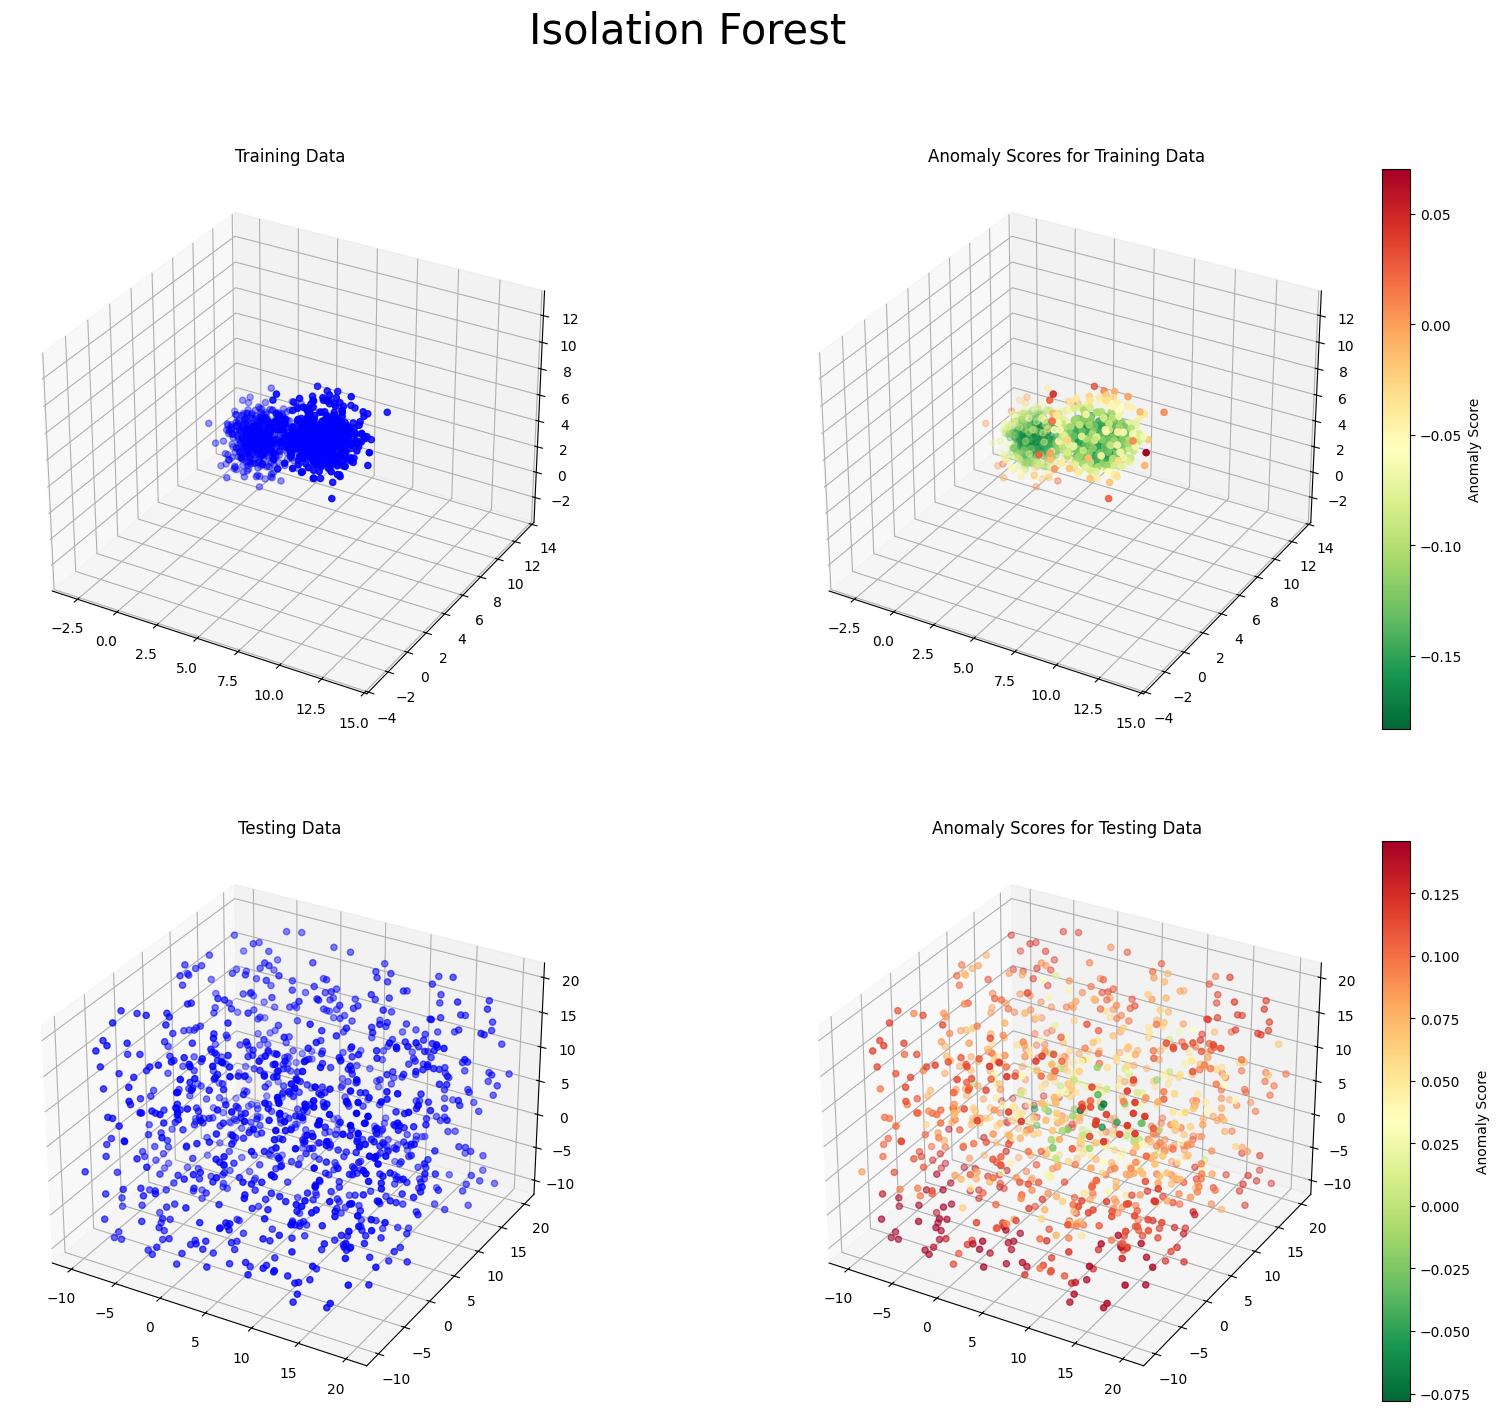

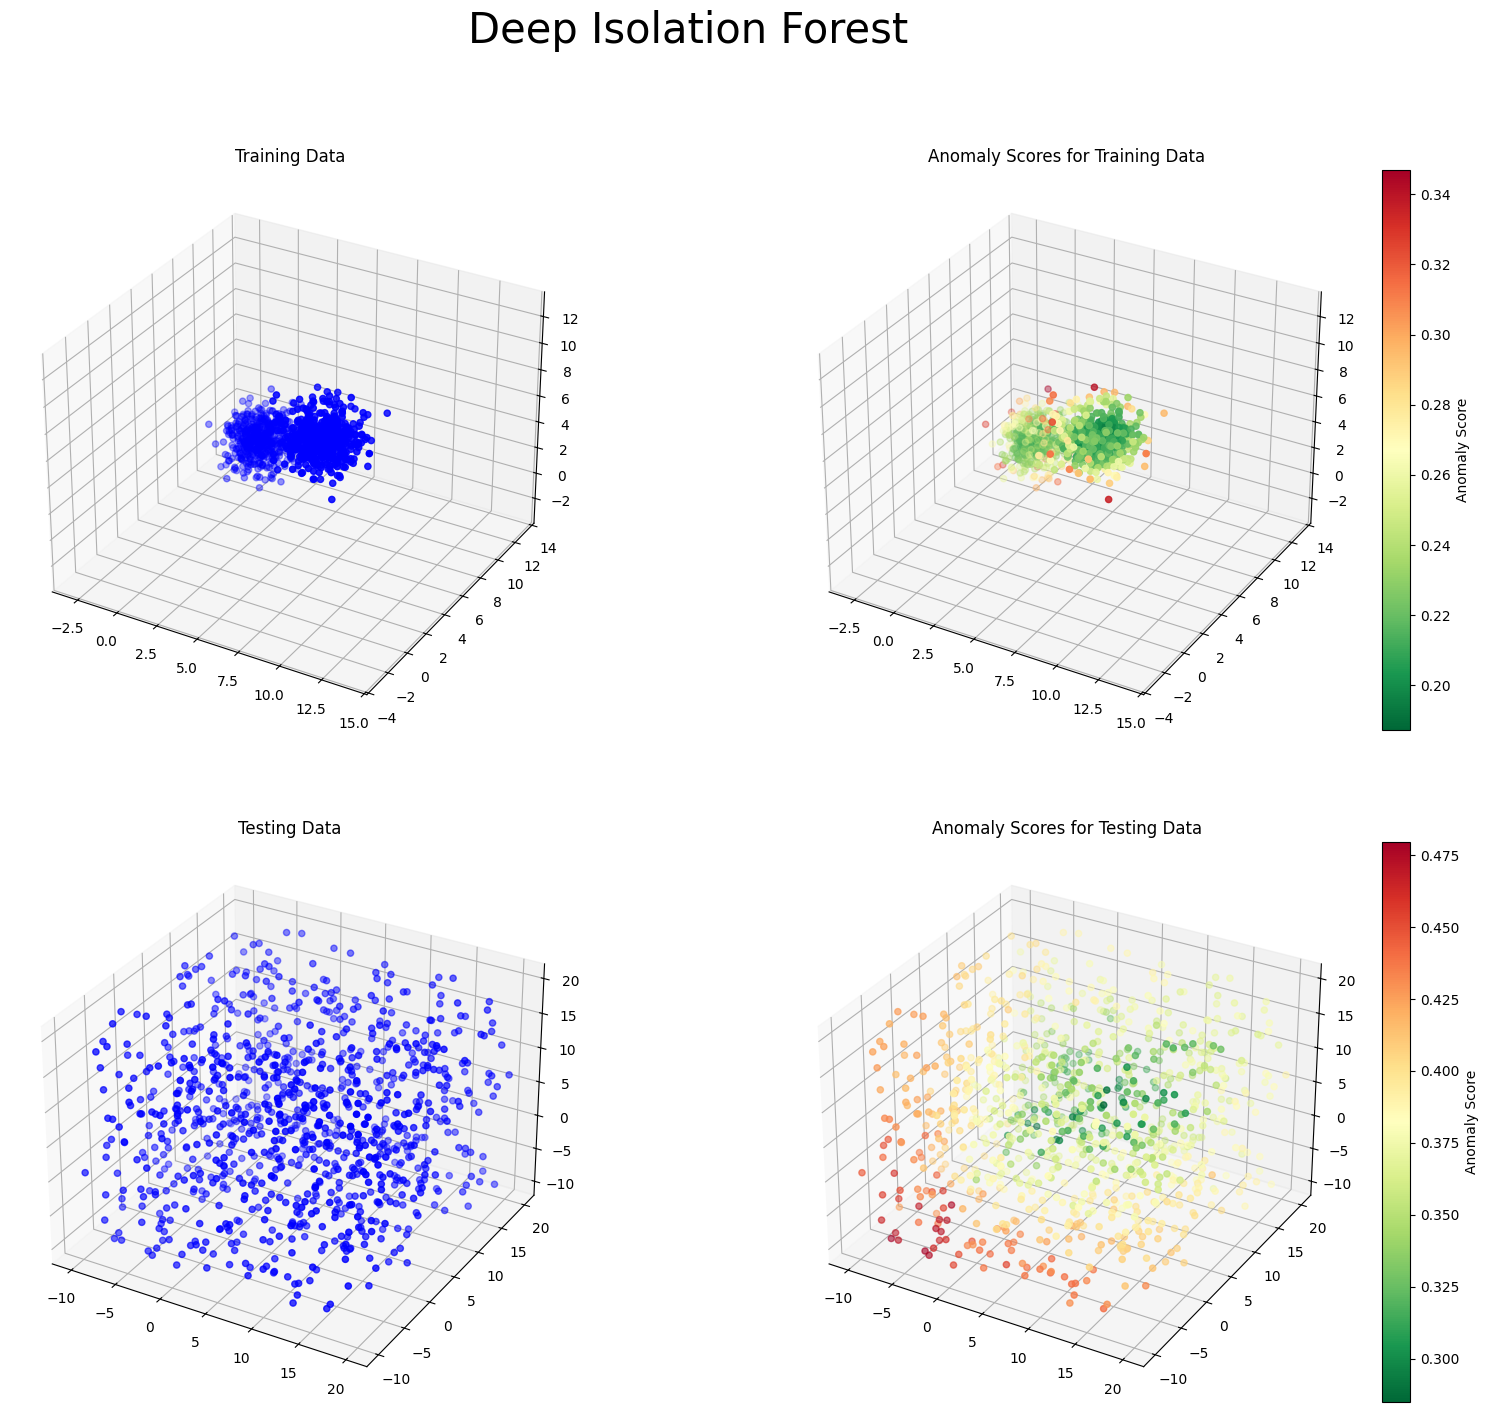

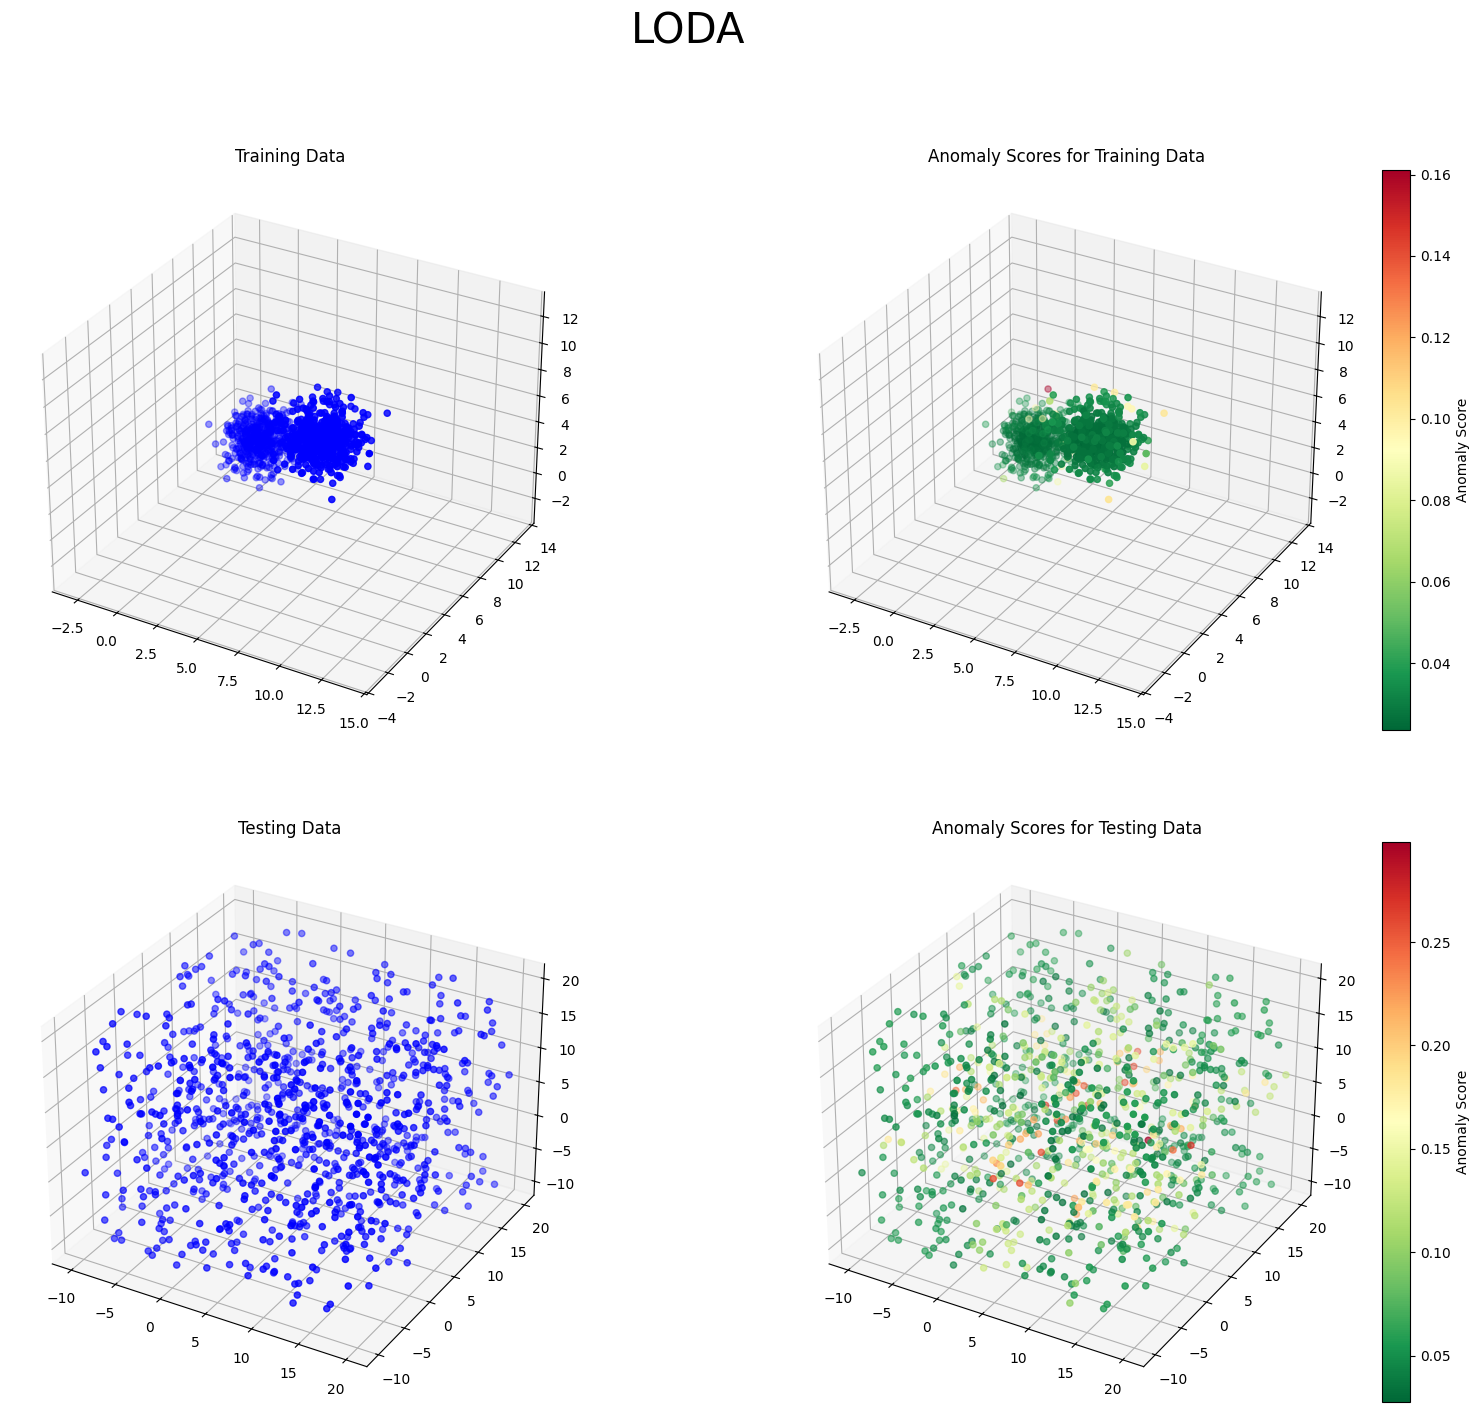

In [68]:
# Ex. 2 - 3D Points

import numpy as np
import matplotlib.pyplot as plt
from pyod.models.iforest import IForest
from pyod.models.dif import DIF
from pyod.models.loda import LODA
from sklearn.datasets import make_blobs

X_train, Y_train = make_blobs(
    n_samples=[500, 500],
    centers=[[0, 10, 0], [10, 0, 10]],
    cluster_std=1,
    random_state=42
)

fig, axes = plt.subplots(2, 2, figsize=(20, 16), subplot_kw={'projection': '3d'})
fig.suptitle("Isolation Forest", fontsize=30)

axes[0, 0].scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], color='blue')
axes[0, 0].set_title('Training Data')

# Isolation Forest

m_IF = IForest(contamination=0.02)
m_IF.fit(X_train)

anmly_score_IF_train = m_IF.decision_scores_

grf1 = axes[0, 1].scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c=anmly_score_IF_train, cmap='RdYlGn_r')
axes[0, 1].set_title('Anomaly Scores for Training Data')

np.random.seed(42)
X_test = np.random.uniform(low=-10, high=20, size=(1000, 3))

axes[1, 0].scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], color='blue')
axes[1, 0].set_title('Testing Data')

anmly_score_IF_test = m_IF.decision_function(X_test)

grf2 = axes[1, 1].scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=anmly_score_IF_test, cmap='RdYlGn_r')
axes[1, 1].set_title('Anomaly Scores for Testing Data')

fig.colorbar(grf1, ax=axes[0,1], label='Anomaly Score')
fig.colorbar(grf2, ax=axes[1,1], label='Anomaly Score')

plt.show()

# Deep Isolation Forest

import warnings

warnings.filterwarnings(
    "ignore",
    message=".*pin_memory.*no accelerator.*",
    category=UserWarning
)

m_DIF = DIF(hidden_neurons=[100, 200, 150], contamination=0.02)
m_DIF.fit(X_train)

anmly_score_DIF_train = m_DIF.decision_scores_
anmly_score_DIF_test = m_DIF.decision_function(X_test)

fig1, axes1 = plt.subplots(2, 2, figsize=(20, 16), subplot_kw={'projection': '3d'})
fig1.suptitle("Deep Isolation Forest", fontsize=30)

axes1[0, 0].scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], color='blue')
axes1[0, 0].set_title('Training Data')

grf3 = axes1[0, 1].scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c=anmly_score_DIF_train, cmap='RdYlGn_r')
axes1[0, 1].set_title('Anomaly Scores for Training Data')

axes1[1, 0].scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], color='blue')
axes1[1, 0].set_title('Testing Data')

grf4 = axes1[1, 1].scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=anmly_score_DIF_test, cmap='RdYlGn_r')
axes1[1, 1].set_title('Anomaly Scores for Testing Data')

fig1.colorbar(grf3, ax=axes1[0,1], label='Anomaly Score')
fig1.colorbar(grf4, ax=axes1[1,1], label='Anomaly Score')

plt.show()

# LODA

m_LODA = LODA(n_bins=30, contamination=0.02)
m_LODA.fit(X_train)

anmly_score_LODA_train = m_LODA.decision_scores_
anmly_score_LODA_test = m_LODA.decision_function(X_test)

fig2, axes2 = plt.subplots(2, 2, figsize=(20, 16), subplot_kw={'projection': '3d'})
fig2.suptitle("LODA", fontsize=30)

axes2[0, 0].scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], color='blue')
axes2[0, 0].set_title('Training Data')

grf5 = axes2[0, 1].scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c=anmly_score_LODA_train, cmap='RdYlGn_r')
axes2[0, 1].set_title('Anomaly Scores for Training Data')

axes2[1, 0].scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], color='blue')
axes2[1, 0].set_title('Testing Data')

grf6 = axes2[1, 1].scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=anmly_score_LODA_test, cmap='RdYlGn_r')
axes2[1, 1].set_title('Anomaly Scores for Testing Data')

fig2.colorbar(grf5, ax=axes2[0,1], label='Anomaly Score')
fig2.colorbar(grf6, ax=axes2[1,1], label='Anomaly Score')

plt.show()


In [79]:
# Ex. 3

from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

data = loadmat('shuttle.mat')

V_BA_IF = []
V_BA_DIF = []
V_BA_LODA = []

V_ROC_AUC_IF = []
V_ROC_AUC_DIF = []
V_ROC_AUC_LODA = []


for i in range(10):

    X_train, X_test, Y_train, Y_test = train_test_split(
        data['X'],
        data['y'],
        test_size=0.4,
        random_state=42 + i
    )

    cnmt = np.mean(Y_train == 1)

    scaler = StandardScaler()
    X_train_std = scaler.fit_transform(X_train)
    X_test_std = scaler.transform(X_test)

    # Isolation Forest

    m_IF = IForest(contamination=cnmt)
    m_IF.fit(X_train_std)
    Y_std_pred_IF = m_IF.predict(X_test_std)

    anmly_score_IF_test = m_IF.decision_function(X_test_std)

    V_BA_IF.append(balanced_accuracy_score(Y_test, Y_std_pred_IF))
    V_ROC_AUC_IF.append(roc_auc_score(Y_test, anmly_score_IF_test))

    # Deep Isolation Forest

    m_DIF = DIF(hidden_neurons=[16], contamination=cnmt)
    m_DIF.fit(X_train_std)
    Y_std_pred_DIF = m_DIF.predict(X_test_std)

    anmly_score_DIF_test = m_DIF.decision_function(X_test_std)

    V_BA_DIF.append(balanced_accuracy_score(Y_test, Y_std_pred_DIF))
    V_ROC_AUC_DIF.append(roc_auc_score(Y_test, anmly_score_DIF_test))

    # LODA

    m_LODA = LODA(n_bins=30, contamination=cnmt)
    m_LODA.fit(X_train_std)
    Y_std_pred_LODA = m_LODA.predict(X_test_std)

    anmly_score_LODA_test = m_LODA.decision_function(X_test_std)

    V_BA_LODA.append(balanced_accuracy_score(Y_test, Y_std_pred_LODA))
    V_ROC_AUC_LODA.append(roc_auc_score(Y_test, anmly_score_LODA_test))



print("All BA Scores for IF (10 data splits):", V_BA_IF)
print("All ROC AUC Scores for IF (10 data splits):", V_ROC_AUC_IF)

print("\n")

print("All BA Scores for DIF (10 data splits):", V_BA_DIF)
print("All ROC AUC Scores for DIF (10 data splits):", V_ROC_AUC_DIF)

print("\n")

print("All BA Scores for LODA (10 data splits):", V_BA_LODA)
print("All ROC AUC Scores for LODA (10 data splits):", V_ROC_AUC_LODA)

print("\n")

print("Mean BA for IF:", np.mean(V_BA_IF))
print("Mean ROC AUC for IF:", np.mean(V_ROC_AUC_IF))

print("\n")

print("Mean BA for DIF:", np.mean(V_BA_DIF))
print("Mean ROC AUC for DIF:", np.mean(V_ROC_AUC_DIF))

print("\n")

print("Mean BA for LODA:", np.mean(V_BA_LODA))
print("Mean ROC AUC for LODA:", np.mean(V_ROC_AUC_LODA))

KeyboardInterrupt: 